In [1]:
import pygad
import axelrod as axl
from axelrod.action import Action, actions_to_str
from axelrod.player import Player
from axelrod.strategy_transformers import (
    FinalTransformer,
    TrackHistoryTransformer,
)
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np
from collections import Counter
import pandas as pd
from math import exp
import numpy as np


In [2]:
C, D = Action.C, Action.D

class FuzzyMethods():
    
    @staticmethod
    def calc_cooperation(self, opponent):
        return (Counter(opponent.history)[C])/len(opponent.history)*100
    
    @staticmethod
    def calc_adaptivity(self, opponent):
        adapCounter = 0
        adapReaction = 0

        if(len(self.history) < 3): 
            return 0
        
        for i in range(3, len(self.history)):
            if (self.history[i-3] == C and self.history[i-2] == D):
                adapCounter += 1
                if (opponent.history[i-1] == D):
                    adapReaction += 1
                elif (self.history[i-1] == D and opponent.history[i] == D):
                    adapReaction += 0.5
            elif (self.history[i-3] == D and self.history[i-2] == C):
                adapCounter += 1
                if (opponent.history[i-1] == C):
                    adapReaction += 1
                elif (self.history[i-1] == C and opponent.history[i] == C):
                    adapReaction += 0.5

        if adapCounter == 0:
            return 0
        
        return adapReaction/adapCounter*100

    
    @staticmethod
    def calc_forgiveness(self, opponent):
        DCounter = 0
        punishmentCounter = 0

        for i in range(0, len(self.history)-1):
            if(self.history[i] == D):
                DCounter += 1
                for j in range (i+1, len(opponent.history)):
                    if(opponent.history[j] == C):
                        break
                    else:
                        punishmentCounter += 1
              

        if punishmentCounter > 0:
            return DCounter/punishmentCounter*100
        else:
            return 100
    
    @staticmethod
    def calc_stochastic(self, opponent):
        patterns = [
            [C, C, C],
            [C, C, D],
            [C, D, C],
            [C, D, D],
            [D, C, C],
            [D, C, D],
            [D, D, C],
            [D, D, D]
        ]

        non_stochasticCounter = 0
        patternPlayedCounter = 0

        for p in patterns:
            opponentsReactions = []
            for i in range(0, len(self.history)-3):
                if ([self.history[i], self.history[i+1], self.history[i+2]] == p):
                    opponentsReactions.append([opponent.history[i+1], opponent.history[i+2], opponent.history[i+3]])
            
            unique_patterns = len(set(tuple(sub) for sub in opponentsReactions))

            if(len(opponentsReactions) > 0):
                non_stochasticCounter += 0 if unique_patterns == 1 else unique_patterns
                patternPlayedCounter += len(opponentsReactions)
        
        if patternPlayedCounter == 0:
            return 0
        
        return non_stochasticCounter/patternPlayedCounter*100

In [3]:
def build_player(params): 
    class FSOptimized(Player):

        name = "FuzzySugeno"
        classifier = {
            "memory_depth": float("inf"),
            "stochastic": False,
            "long_run_time": False,
            "inspects_source": False,
            "manipulates_source": False,
            "manipulates_state": False,
        }

        cooperation = ctrl.Antecedent(np.arange(0, 100, 1), 'cooperation')
        adaptivity = ctrl.Antecedent(np.arange(0, 100, 1), 'adaptivity')
        forgiveness = ctrl.Antecedent(np.arange(0, 100, 1), 'forgiveness')
        stochastic = ctrl.Antecedent(np.arange(0, 100, 1), 'stochastic')

        cooperation.automf(names=["low", "medium", "high"])
        adaptivity.automf(names=["no", "yes"])
        forgiveness.automf(names=["low", "medium", "high"])
        forgiveness['low'] = fuzz.gaussmf(forgiveness.universe, 0, 25)
        forgiveness['medium'] = fuzz.trimf(forgiveness.universe, [25, 50, 75])
        stochastic.automf(names=["none", "sometimes", "always"])

        resulting_strategy = ctrl.Consequent(np.arange(0, 100, 1),'resulting_strategy')
        resulting_strategy['D'] = fuzz.trimf(resulting_strategy.universe, [0, 25, 50])
        resulting_strategy['C'] = fuzz.trimf(resulting_strategy.universe, [35, 75, 100])

        paramsMatrix = np.array(params).reshape(-1, 5)

        rules = []

        for ruleVector in paramsMatrix:
            coop = None  if ruleVector[0] == 0 else "low" if ruleVector[0] == 1 else "medium" if ruleVector[0] == 2 else "high"
            adap = None if ruleVector[1] == 0 else "no" if ruleVector[1] == 1 else "yes"
            forg = None if ruleVector[2] == 0 else "low" if ruleVector[2] == 1 else "medium" if ruleVector[2] == 2  else "high"
            stoch = None if ruleVector[3] == 0 else "none" if ruleVector[3] == 1 else "sometimes" if ruleVector[3] == 2 else "always"
            res = "D" if ruleVector[4] == 0 else "C"

            antecedents = []

            if coop is not None:
                antecedents.append(cooperation[coop])

            if adap is not None:
                antecedents.append(adaptivity[adap])

            if forg is not None:
                antecedents.append(forgiveness[forg])

            if stoch is not None:
                antecedents.append(stochastic[stoch])

            if len(antecedents) == 0:
                continue 

            rule_lhs = antecedents[0]
            for a in antecedents[1:]:
                rule_lhs = rule_lhs & a

            rule = ctrl.Rule(rule_lhs, resulting_strategy[res])
            rules.append(rule)

        strategy_ctrl = ctrl.ControlSystem(rules)
        chosen_strategy = ctrl.ControlSystemSimulation(strategy_ctrl)


        h = {'Name':'', 'Fuzzy' : [], 'Opponent': []}

        forgiveness_index = 0
        stochastic_index = 0
        first_time = True
    
        def strategy(self, opponent: Player) -> Action:

            if(len(self.history) == 0 or D not in opponent.history):
                return C
            
            else:
                coop = FuzzyMethods.calc_cooperation(self, opponent)
                adap = FuzzyMethods.calc_adaptivity(self, opponent)
                forg = FuzzyMethods.calc_forgiveness(self, opponent)
                stoch = FuzzyMethods.calc_stochastic(self, opponent)

                self.chosen_strategy.input['cooperation'] = coop
                self.chosen_strategy.input['adaptivity'] = adap
                self.chosen_strategy.input['forgiveness'] = forg
                self.chosen_strategy.input['stochastic'] = stoch
                
                self.chosen_strategy.compute()

                try:
                    output = self.chosen_strategy.output['resulting_strategy']
                except Exception as e:
                    return C  # Default to cooperation if there's an error

                if output > 50:
                    return C
                else:
                    return D
            
            return C
    return FSOptimized()

In [4]:
i = 0
def fitness_function(ga_instance, solution, solution_idx):
    global i
    print(f"Evaluating solution {i} {solution_idx}: {solution}")
    if solution_idx == 3:
        i+=1
    results = axl.Tournament(players=[build_player(solution)] + [player() for player in axl.stewart_plotkin_strategies], turns=200).play(progress_bar=False)
    # results = axl.Tournament(players=[build_player(solution), axl.TitForTat(), axl.Prober()], turns=200).play(progress_bar=False)
    return np.mean(results.normalised_scores[0])


In [5]:
num_generations = 50
num_parents_mating = 4

# sol_per_pop = 8
# num_genes = 2

init_range_low = 0
init_range_high = 1

parent_selection_type = "sss"
keep_parents = 1

crossover_type = "single_point"

mutation_type = "random"
mutation_percent_genes = 10

gene_space_1 = [
    # Rule 1
    [0,1,2,3],
    [0,1,2],
    [0, 1,2,3],
    [0,1,2,3],
    [0,1],
]

gene_space = gene_space_1 * 8

initial_population = [
    [3, 1, 2, 0, 1, 3, 1, 3, 0, 1, 3, 0, 1, 0, 0, 0, 0, 0, 3, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 2, 0, 1, 0, 1, 2, 2, 2, 0, 1],
    [3, 1, 2, 0, 0, 3, 1, 3, 0, 0, 3, 0, 1, 0, 1, 0, 0, 0, 3, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 2, 0, 1, 0, 0, 2, 2, 2, 0, 0],
    [1, 2, 1, 0, 0, 2, 2, 1, 3, 1, 1, 1, 2, 3, 1, 2, 2, 2, 3, 0, 0, 2, 1, 0, 1, 1, 2, 0, 2, 0, 2, 2, 1, 0, 0, 0, 0, 2, 1, 1],
    [2, 0, 3, 1, 0, 1, 2, 2, 2, 1, 2, 1, 2, 1, 1, 2, 2, 0, 3, 1, 1, 2, 2, 3, 0, 0, 2, 1, 2, 0, 0, 1, 0, 3, 0, 2, 2, 1, 2, 1]
]

In [6]:
ga_instance = pygad.GA(num_generations=num_generations,
                       num_parents_mating=num_parents_mating,
                       fitness_func=fitness_function,
                       initial_population=initial_population,
                       gene_space=gene_space,
                       gene_type=int,
                       parent_selection_type=parent_selection_type,
                       keep_parents=keep_parents,
                       crossover_type=crossover_type,
                       mutation_type=mutation_type,
                       mutation_percent_genes=mutation_percent_genes)

In [7]:
ga_instance.run()

Evaluating solution 0 0: [3 1 2 0 1 3 1 3 0 1 3 0 1 0 0 0 0 0 3 1 0 1 0 0 1 1 0 0 0 1 2 0 1 0 1 2 2
 2 0 1]
Evaluating solution 0 1: [3 1 2 0 0 3 1 3 0 0 3 0 1 0 1 0 0 0 3 0 0 1 0 0 0 1 0 0 0 0 2 0 1 0 0 2 2
 2 0 0]
Evaluating solution 0 2: [1 2 1 0 0 2 2 1 3 1 1 1 2 3 1 2 2 2 3 0 0 2 1 0 1 1 2 0 2 0 2 2 1 0 0 0 0
 2 1 1]
Evaluating solution 0 3: [2 0 3 1 0 1 2 2 2 1 2 1 2 1 1 2 2 0 3 1 1 2 2 3 0 0 2 1 2 0 0 1 0 3 0 2 2
 1 2 1]
Evaluating solution 1 1: [3 1 3 0 1 3 1 3 1 1 3 0 1 0 0 0 0 2 3 1 0 1 0 0 1 1 0 0 3 1 2 0 1 0 0 0 0
 2 1 1]
Evaluating solution 1 2: [1 2 1 0 0 2 2 1 3 1 1 1 2 3 1 2 2 2 3 0 2 2 1 0 0 1 2 0 2 0 2 1 1 0 1 2 2
 2 0 0]
Evaluating solution 1 3: [3 1 2 0 0 1 2 2 2 1 2 1 2 1 1 2 2 0 3 1 1 2 2 3 0 0 2 0 2 0 0 2 0 2 0 2 2
 1 2 0]
Evaluating solution 2 1: [3 1 2 0 1 3 1 3 0 1 3 1 1 0 1 2 0 0 3 1 3 2 2 3 0 0 0 0 2 0 0 2 0 2 0 2 2
 1 2 0]
Evaluating solution 2 2: [3 1 2 0 0 1 2 2 2 0 2 1 2 1 1 2 2 0 3 1 3 2 1 0 0 1 2 0 2 0 0 1 1 0 0 2 2
 2 0 0]
Evaluating solution 2 3: [1 

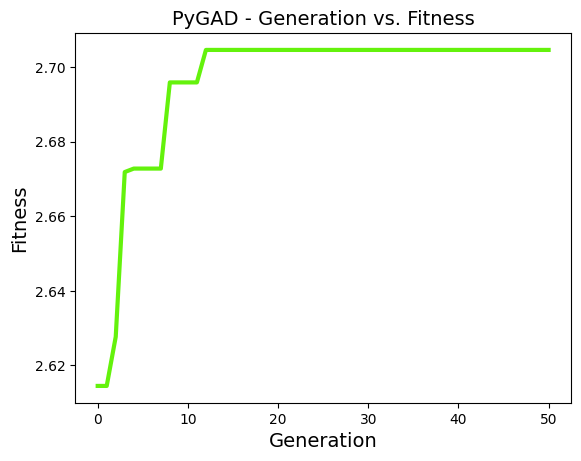

Parameters of the best solution : [3 0 2 0 1 1 2 3 2 0 3 1 1 0 0 2 0 0 2 0 0 1 2 0 0 2 1 0 1 1 3 1 3 0 1 0 1
 1 0 0]
Fitness value of the best solution = 2.7046071428571428


In [10]:
solution, solution_fitness, solution_idx = ga_instance.best_solution()
ga_instance.plot_fitness()
ga_instance.save("ga_results")
print("Parameters of the best solution : {solution}".format(solution=solution))
print("Fitness value of the best solution = {solution_fitness}".format(solution_fitness=solution_fitness))

In [20]:
for ruleVector in solution.reshape(-1, 5):
    string = ""
    coop = None  if ruleVector[0] == 0 else "Coop = low" if ruleVector[0] == 1 else "Coop = medium" if ruleVector[0] == 2 else "Coop = high"
    adap = None if ruleVector[1] == 0 else " & Adap = no" if ruleVector[1] == 1 else " & Adap = yes"
    forg = None if ruleVector[2] == 0 else " & Forg = low" if ruleVector[2] == 1 else " & Forg = medium" if ruleVector[2] == 2  else " & Forg = high"
    stoch = None if ruleVector[3] == 0 else " & Stoch = none" if ruleVector[3] == 1 else " & Stoch = sometimes" if ruleVector[3] == 2 else " & Stoch = always"
    res = "D" if ruleVector[4] == 0 else "C"
    print(f" {coop if coop else ''}{adap if adap else ''}{forg if forg else ''}{stoch if stoch else ''} => {res}")

 Coop = high & Forg = medium => C
 Coop = low & Adap = yes & Forg = high & Stoch = sometimes => D
 Coop = high & Adap = no & Forg = low => D
 Coop = medium & Stoch = sometimes => D
  & Adap = no & Forg = medium => D
 Coop = medium & Adap = no & Stoch = none => C
 Coop = high & Adap = no & Forg = high => C
  & Adap = no & Forg = low => D
